# 01 · Feature questions (spec 17)

The towers and the ranker were built on reasonable hunches. This notebook checks them against the
data, one question per section, and ends with a findings table that each section fills in as it
runs:

| # | Question |
|---|---|
| Q1 | Do heavy users review games only in a specific cluster of genres / tags? |
| Q2 | Can review reactions (voted useful, voted funny) be used to weight the interactions? |
| Q3 | Does game age influence a user's review? |
| Q4 | Is a game's price related to its number of reviews and popularity (free games)? |
| Q5 | Does the order of a user's recent history matter for the next interaction (attention)? |
| Q6 | Do embeddings of the game descriptions cluster games with a similar premise and features? |
| Q7 | Are negative reviews an important signal for the model? |
| Q8 | Is sentiment analysis of a game's top reviews useful as a feature? |
| E1 | Is playtime at review a better interaction weight than votes? |
| E2 | Are users loyal to developers? |
| E3 | Is popularity stable over time, or is a time-aware popularity feature needed? |
| E4 | Does the reviewer's language say something about the games they pick? |

**How to read the numbers.** A raw concentration or similarity mixes taste with popularity: everyone
reviews Counter-Strike. So most sections compare against a **null model** that keeps the parts we
don't want to credit and destroys the rest. `shuffle_games` permutes games across reviews, which
keeps each user's activity and each game's popularity but breaks who-reviewed-what. `shuffle_order`
randomizes the order of each user's reviews. A signal exists only if it beats its null.

**Data.** The public dataset (spec 16, `sergiodelcarpio/steam-reviews`): `reviews*.parquet`
(121M reviews), `games.parquet`, `game_tags.parquet` in `notebooks/data/` (or `EDA_DATA_DIR`). User
analyses use a hash sample of users (`EDA_SAMPLE_USERS`, default 5%), with whole histories.
Catalog-wide counts (reviews per game, time windows) use every review. Caveats: `game_price` is the
price at the last scrape, and `votes_*` / `playtime_forever` / `num_*` are measured at scrape time,
not at review time.

In [1]:
import math
from datetime import timedelta

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import seaborn as sns
from IPython.display import Markdown, display

from steam_eda import (
    auc,
    binned_mean,
    cached,
    consecutive_pairs,
    gini,
    jaccard,
    lag_similarity,
    load_games,
    load_reviews,
    nlp,
    profile_fit,
    scan,
    sequence,
    settings,
    shuffle_games,
    shuffle_order,
    smoothed_ratio,
    spearman,
    user_concentration,
)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (11, 4)
pl.Config.set_tbl_rows(25)
pl.Config.set_fmt_str_lengths(70)

S = settings()
SEED = S.seed
HEAVY = 20  # "heavy user": at least this many reviews
MAX_USER_REVIEWS = (
    1000  # above this a "user" is likely a bot / review farm: left out of user analyses
)
TOP_TAGS_PER_GAME = 10  # Steam user tags come by vote weight; the first ones define the game
print(f"data: {S.data_dir}  sample: {S.sample_users:.1%} of users  text models: {S.text_models}")

findings: list[dict] = []


def note(question: str, evidence: str, verdict: str) -> None:
    findings.append({"question": question, "evidence": evidence, "verdict": verdict})
    display(Markdown(f"**{question}** · {evidence}\n\n→ {verdict}"))

data: /home/sadelcarpio/code/steam-recsys-e2e/notebooks/data  sample: 5.0% of users  text models: auto


## Data

`games` has one row per game with its tags and lifetime review counts (from every review). `reviews`
is the user sample, without the review text.

In [2]:
games = load_games()
counts = cached(
    "game_counts",
    lambda: (
        scan("reviews")
        .group_by("game_id")
        .agg(reviews=pl.len(), positives=pl.col("is_positive").sum())
        .collect(engine="streaming")
    ),
)
games = games.join(counts, on="game_id", how="left").with_columns(
    pl.col("reviews", "positives").fill_null(0),
    is_free=pl.col("game_is_free").fill_null(False) | (pl.col("game_price") == 0),
    released=~pl.col("game_coming_soon").fill_null(False),
)
SNAPSHOT = scan("reviews").select(pl.col("reviewed_at").max()).collect().item()

reviews = load_reviews().join(games.select("game_id"), on="game_id", how="semi")
activity = reviews.group_by("user_id").agg(n=pl.len())
reviews = reviews.join(activity.filter(pl.col("n") <= MAX_USER_REVIEWS), on="user_id", how="semi")
activity = activity.filter(pl.col("n") <= MAX_USER_REVIEWS)

TAGS = games.select("game_id", tags=pl.col("tag_names").list.head(TOP_TAGS_PER_GAME).fill_null([]))
TOP3 = games.select("game_id", tags=pl.col("tag_names").list.head(3).fill_null([]))
GENRES = games.select("game_id", genres=pl.col("game_genres").fill_null([]))
DEVELOPERS = games.select("game_id", developers=pl.col("game_developers").fill_null([]))


def bucket(n: pl.Expr) -> pl.Expr:
    return (
        pl.when(n < 5)
        .then(pl.lit("01-04"))
        .when(n < 10)
        .then(pl.lit("05-09"))
        .when(n < HEAVY)
        .then(pl.lit(f"10-{HEAVY - 1}"))
        .when(n < 50)
        .then(pl.lit(f"{HEAVY}-49"))
        .otherwise(pl.lit("50+"))
    )


print(
    f"snapshot {SNAPSHOT:%Y-%m-%d}; {games.height:,d} games, {games['reviews'].sum():,d} reviews in total"
)
print(
    f"sample: {reviews.height:,d} reviews by {activity.height:,d} users "
    f"({activity.filter(pl.col('n') >= HEAVY).height:,d} heavy, ≥{HEAVY} reviews)"
)
activity.group_by(bucket(pl.col("n")).alias("reviews_per_user")).agg(
    users=pl.len(), reviews=pl.col("n").sum()
).with_columns(
    share_users=pl.col("users") / pl.col("users").sum(),
    share_reviews=pl.col("reviews") / pl.col("reviews").sum(),
).sort("reviews_per_user")

snapshot 2026-10-30; 184,885 games, 120,980,379 reviews in total
sample: 6,014,867 reviews by 1,943,048 users (33,865 heavy, ≥20 reviews)


reviews_per_user,users,reviews,share_users,share_reviews
str,u32,u32,f64,f64
"""01-04""",1665912,2627845,0.85737,0.436892
"""05-09""",174957,1116122,0.090043,0.185561
"""10-19""",68314,895621,0.035158,0.148901
"""20-49""",27505,790875,0.014156,0.131487
"""50+""",6360,584404,0.003273,0.09716


## Q1 · Do heavy users stay in a cluster of genres / tags?

For each user: `top_share` is the share of their games carrying their most common label, and
`effective_labels` is 2^entropy of their label counts (how many labels they effectively spread
over). Labels are a game's **top 3 tags** (tags are fine-grained, ~450 of them) and Steam's
**genres** (~30 coarse ones, Indie and Action are on most games). The null is the same users with
shuffled games. The test: what share of heavy users is more concentrated than 95% of the shuffled
users of the same activity bucket.

In [3]:
def concentration(labels: pl.DataFrame, label: str) -> pl.DataFrame:
    real = user_concentration(reviews, labels, label, min_reviews=5).with_columns(
        model=pl.lit("observed")
    )
    null = user_concentration(
        shuffle_games(reviews, SEED), labels, label, min_reviews=5
    ).with_columns(model=pl.lit("shuffled"))
    return pl.concat([real, null]).with_columns(
        activity=bucket(pl.col("n_games")), label=pl.lit(label)
    )


conc = pl.concat([concentration(TOP3, "tags"), concentration(GENRES, "genres")])
p95 = (
    conc.filter(pl.col("model") == "shuffled")
    .group_by("label", "activity")
    .agg(p95=pl.col("top_share").quantile(0.95))
)
q1 = (
    conc.filter(pl.col("model") == "observed")
    .join(p95, on=["label", "activity"])
    .group_by("label", "activity")
    .agg(users=pl.len(), above_null_p95=(pl.col("top_share") > pl.col("p95")).mean())
    .join(
        conc.group_by("label", "activity").agg(
            top_share_observed=pl.col("top_share").filter(pl.col("model") == "observed").median(),
            top_share_shuffled=pl.col("top_share").filter(pl.col("model") == "shuffled").median(),
            eff_labels_observed=pl.col("effective_labels")
            .filter(pl.col("model") == "observed")
            .median(),
            eff_labels_shuffled=pl.col("effective_labels")
            .filter(pl.col("model") == "shuffled")
            .median(),
        ),
        on=["label", "activity"],
    )
    .sort("label", "activity")
)
q1

label,activity,users,above_null_p95,top_share_observed,top_share_shuffled,eff_labels_observed,eff_labels_shuffled
str,str,u32,f64,f64,f64,f64,f64
"""genres""","""05-09""",174521,0.0,0.8,0.666667,6.061107,6.822419
"""genres""","""10-19""",68082,0.2367,0.736842,0.642857,6.647788,7.763717
"""genres""","""20-49""",27395,0.362657,0.72,0.621622,6.937267,8.336071
"""genres""","""50+""",6332,0.507738,0.705882,0.609756,7.076656,8.688623
"""tags""","""05-09""",174844,0.112495,0.4,0.333333,13.675837,15.430392
"""tags""","""10-19""",68256,0.307138,0.352941,0.272727,21.986501,26.968916
"""tags""","""20-49""",27474,0.381015,0.304348,0.222222,33.275555,43.444148
"""tags""","""50+""",6356,0.59314,0.284021,0.196078,49.418334,68.241319


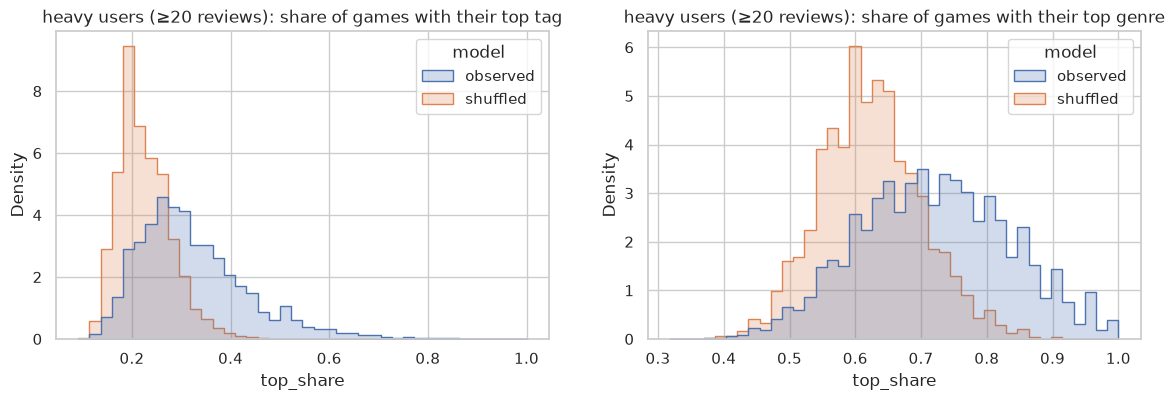

model,top_label,users,share,shuffled_share
str,str,u32,f64,f64
"""observed""","""Action""",9724,0.287437,0.290996
"""observed""","""Multiplayer""",3896,0.115164,0.44495
"""observed""","""Strategy""",2662,0.078688,0.023289
"""observed""","""RPG""",2453,0.07251,0.025055
"""observed""","""Open World""",1969,0.058203,0.076573
"""observed""","""Horror""",1354,0.040024,0.010717
"""observed""","""FPS""",1317,0.03893,0.027061
"""observed""","""Simulation""",1303,0.038516,0.021403
"""observed""","""Adventure""",1293,0.038221,0.012782


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, label in zip(axes, ["tags", "genres"], strict=True):
    data = conc.filter((pl.col("label") == label) & (pl.col("n_games") >= HEAVY))
    sns.histplot(
        data=data.to_pandas(),
        x="top_share",
        hue="model",
        stat="density",
        common_norm=False,
        bins=40,
        element="step",
        ax=ax,
    )
    ax.set_title(f"heavy users (≥{HEAVY} reviews): share of games with their top {label[:-1]}")
plt.show()

heavy_top = (
    conc.filter((pl.col("label") == "tags") & (pl.col("n_games") >= HEAVY))
    .group_by("model", "top_label")
    .agg(users=pl.len())
    .with_columns(share=pl.col("users") / pl.col("users").sum().over("model"))
    .sort("users", descending=True)
)
heavy_top.filter(pl.col("model") == "observed").head(15).join(
    heavy_top.filter(pl.col("model") == "shuffled").select("top_label", shuffled_share="share"),
    on="top_label",
    how="left",
)

In [5]:
def heavy_above(label: str) -> float:
    h = q1.filter((pl.col("label") == label) & pl.col("activity").is_in([f"{HEAVY}-49", "50+"]))
    return (
        float((h["above_null_p95"] * h["users"]).sum() / h["users"].sum()) if h.height else math.nan
    )


tags_above, genres_above = heavy_above("tags"), heavy_above("genres")
note(
    "Q1 heavy users stay in a tag / genre cluster",
    f"{tags_above:.0%} of heavy users are more concentrated on their top tag than 95% of shuffled "
    f"users (genres: {genres_above:.0%}; 5% expected by chance)",
    (
        "Yes, taste is clustered beyond popularity: give the user tower the tag profile of the "
        "history (multi-hot / pooled tag embeddings), not only game ids; tags beat genres."
        if tags_above > 0.25
        else "Weak: heavy users spread over many tags, so a tag profile adds little beyond game ids."
    )
    + (" Genres are too coarse to tell users apart." if genres_above < tags_above / 2 else ""),
)

**Q1 heavy users stay in a tag / genre cluster** · 42% of heavy users are more concentrated on their top tag than 95% of shuffled users (genres: 39%; 5% expected by chance)

→ Yes, taste is clustered beyond popularity: give the user tower the tag profile of the history (multi-hot / pooled tag embeddings), not only game ids; tags beat genres.

## Q2 · Can votes (useful / funny) weight the interactions? (+ E1: playtime)

A good interaction weight should say how much the review tells about **the reviewer's taste**. Two
checks:

1. **Bias.** Votes are counted at scrape time, so they grow with the review's age and the game's
   audience. A raw vote weight would mostly upweight old reviews of popular games.
2. **Taste.** `fit` is how well the reviewed game matches the user's other games (leave-one-out
   tag overlap, users with 5+ reviews). If highly voted reviews were "more representative", `fit`
   would rise with votes. Playtime at review (measured at review time, E1) is the natural
   alternative weight.

In [6]:
eval_users = activity.filter(pl.col("n") >= 5)
r2 = reviews.join(eval_users, on="user_id", how="semi").with_columns(
    # the Steam API reports some funny counts as 2^32 - 1 (an unsigned -1): unknown, not viral
    votes_funny=pl.when(pl.col("votes_funny") < 1_000_000).then(pl.col("votes_funny"))
)
r2 = (
    r2.join(profile_fit(r2, r2, TAGS, "tags"), on="review_id", how="left")
    .join(games.select("game_id", game_reviews="reviews"), on="game_id", how="left")
    .with_columns(
        review_age_days=(pl.lit(SNAPSHOT) - pl.col("reviewed_at")).dt.total_days(),
        playtime_hours=pl.col("playtime_at_review") / 60,
    )
)
pl.DataFrame(
    [
        {
            "field": f,
            "share_nonzero": float((r2[f] > 0).mean()),
            "p50": float(r2[f].quantile(0.5)),
            "p90": float(r2[f].quantile(0.9)),
            "p99": float(r2[f].quantile(0.99)),
            "max": float(r2[f].max()),
        }
        for f in [
            "votes_up",
            "votes_funny",
            "weighted_vote_score",
            "comment_count",
            "playtime_hours",
        ]
    ]
)

field,share_nonzero,p50,p90,p99,max
str,f64,f64,f64,f64,f64
"""votes_up""",0.364933,0.0,4.0,40.0,20104.0
"""votes_funny""",0.132767,0.0,1.0,8.0,6809.0
"""weighted_vote_score""",1.0,0.5,0.541985,0.743745,0.993641
"""comment_count""",0.051192,0.0,0.0,3.0,2005.0
"""playtime_hours""",1.0,10.116667,93.883333,846.783333,50652.35


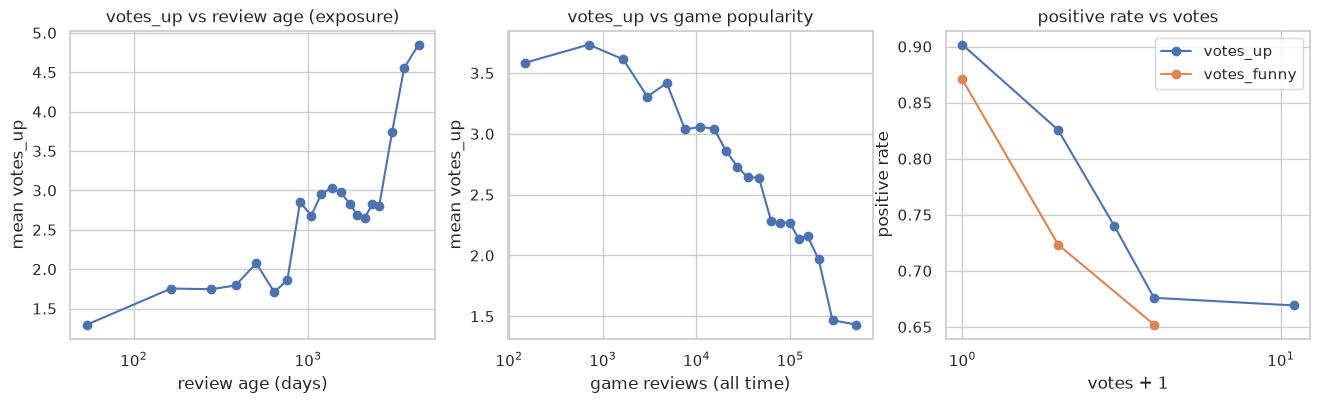

weight,spearman_with_fit,spearman_with_is_positive,spearman_with_review_age
str,f64,f64,f64
"""votes_up""",-0.017347,-0.221138,0.092958
"""votes_funny""",-0.019014,-0.167268,0.092781
"""weighted_vote_score""",-0.009726,0.107979,-0.00259
"""playtime_at_review""",0.071845,0.137632,-0.055163


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
b = binned_mean(r2, "review_age_days", "votes_up", bins=20)
axes[0].plot(b["x"], b["mean"], marker="o")
axes[0].set_xscale("log")
axes[0].set(
    title="votes_up vs review age (exposure)", xlabel="review age (days)", ylabel="mean votes_up"
)
b = binned_mean(r2, "game_reviews", "votes_up", bins=20)
axes[1].plot(b["x"], b["mean"], marker="o")
axes[1].set_xscale("log")
axes[1].set(
    title="votes_up vs game popularity", xlabel="game reviews (all time)", ylabel="mean votes_up"
)
for field in ["votes_up", "votes_funny"]:
    b = binned_mean(r2.with_columns(pl.col(field).clip(0, 1000)), field, "is_positive", bins=10)
    axes[2].plot(b["x"] + 1, b["mean"], marker="o", label=field)
axes[2].set_xscale("log")
axes[2].legend()
axes[2].set(title="positive rate vs votes", xlabel="votes + 1", ylabel="positive rate")
plt.show()

taste = pl.DataFrame(
    [
        {
            "weight": f,
            "spearman_with_fit": spearman(r2[f].cast(pl.Float64), r2["fit"]),
            "spearman_with_is_positive": spearman(
                r2[f].cast(pl.Float64), r2["is_positive"].cast(pl.Float64)
            ),
            "spearman_with_review_age": spearman(
                r2[f].cast(pl.Float64), r2["review_age_days"].cast(pl.Float64)
            ),
        }
        for f in ["votes_up", "votes_funny", "weighted_vote_score", "playtime_at_review"]
    ]
)
taste

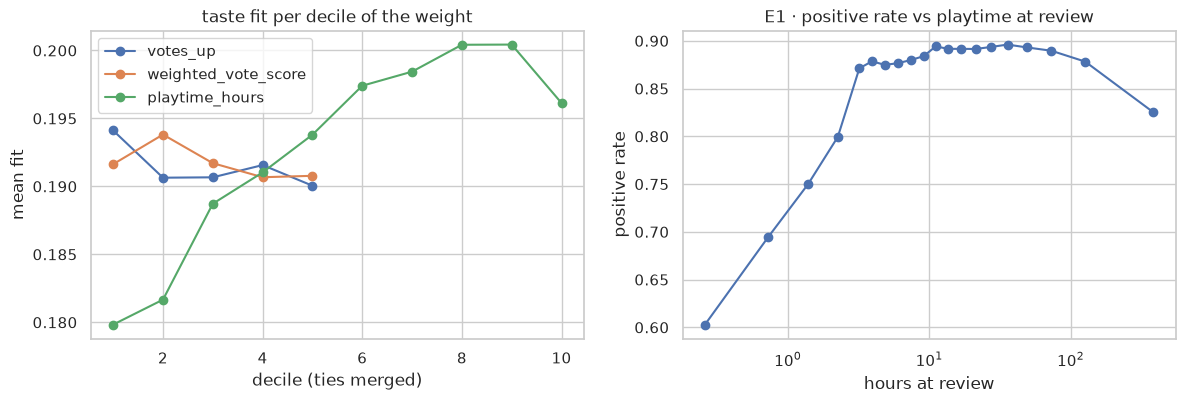

**Q2 votes as interaction weights** · 36% of reviews have a useful vote, 13% a funny one; ρ(votes_up, taste fit) = -0.017, ρ(votes_up, review age) = +0.093

→ Don't weight by votes: they measure how visible the review was (age, game audience), not how strongly the reviewer cares. Keep them, if anything, to pick review texts (Q8).

**E1 playtime at review as weight** · ρ(playtime, taste fit) = +0.072, ρ(playtime, positive) = +0.138

→ Playtime is the better engagement weight (measured at review time, no exposure bias): try log1p(hours) as a sample weight or a ranker feature.

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for field in ["votes_up", "weighted_vote_score", "playtime_hours"]:
    b = binned_mean(r2, field, "fit", bins=10)
    axes[0].plot(b["x"].rank("ordinal"), b["mean"], marker="o", label=field)
axes[0].set(
    title="taste fit per decile of the weight", xlabel="decile (ties merged)", ylabel="mean fit"
)
axes[0].legend()
b = binned_mean(r2, "playtime_hours", "is_positive", bins=20)
axes[1].plot(b["x"] + 0.01, b["mean"], marker="o")
axes[1].set_xscale("log")
axes[1].set(
    title="E1 · positive rate vs playtime at review",
    xlabel="hours at review",
    ylabel="positive rate",
)
plt.show()

rho = {r["weight"]: r for r in taste.iter_rows(named=True)}
note(
    "Q2 votes as interaction weights",
    f"{(r2['votes_up'] > 0).mean():.0%} of reviews have a useful vote, {(r2['votes_funny'] > 0).mean():.0%} "
    f"a funny one; ρ(votes_up, taste fit) = {rho['votes_up']['spearman_with_fit']:+.3f}, "
    f"ρ(votes_up, review age) = {rho['votes_up']['spearman_with_review_age']:+.3f}",
    (
        "Don't weight by votes: they measure how visible the review was (age, game audience), not how "
        "strongly the reviewer cares. Keep them, if anything, to pick review texts (Q8)."
        if abs(rho["votes_up"]["spearman_with_fit"]) < 0.05
        else "Votes track taste fit: a log1p(votes) weight, normalized by review age, is worth an ablation."
    ),
)
pt = rho["playtime_at_review"]
note(
    "E1 playtime at review as weight",
    f"ρ(playtime, taste fit) = {pt['spearman_with_fit']:+.3f}, ρ(playtime, positive) = "
    f"{pt['spearman_with_is_positive']:+.3f}",
    (
        "Playtime is the better engagement weight (measured at review time, no exposure bias): try "
        "log1p(hours) as a sample weight or a ranker feature."
        if abs(pt["spearman_with_fit"]) > abs(rho["votes_up"]["spearman_with_fit"])
        or abs(pt["spearman_with_is_positive"]) > 0.05
        else "Playtime carries little taste signal either: keep interactions unweighted."
    ),
)

## Q3 · Does game age influence the review?

Game age at review = review date − release date (exact release dates only). Two separate effects:
**volume** (do reviews come early in a game's life? then age / recency is an item feature for
retrieval) and **sentiment** (does a game's positive rate change as it ages?). Comparing the
early and late positive rate *within the same game* (every review, games with 30+ reviews on each
side) removes the mix of good and bad games.

In [9]:
release = games.select("game_id", "release_date", "release_year")
r3 = reviews.join(release, on="game_id", how="left").with_columns(
    age_days=(pl.col("reviewed_at").dt.date() - pl.col("release_date")).dt.total_days()
)
known = r3.filter(pl.col("age_days").is_not_null())
print(
    f"exact release date known for {known.height / r3.height:.0%} of reviews; "
    f"{(known['age_days'] < 0).mean():.1%} written before release (early access / pre-release keys)"
)
ages = known.filter(pl.col("age_days") >= 0)["age_days"]
# what the first-year share would be if each game's reviews were spread evenly over its life so far
lifetime = (pl.lit(SNAPSHOT.date()) - pl.col("release_date")).dt.total_days().clip(1)
expected_first_year = float(
    known.filter(pl.col("age_days") >= 0).select((365 / lifetime).clip(0, 1).mean()).item()
)
print(f"first-year share if reviews were uniform over each game's life: {expected_first_year:.0%}")
pl.DataFrame(
    {
        "within_days": [7, 30, 90, 365, 365 * 3],
        "share_of_reviews": [float((ages <= d).mean()) for d in [7, 30, 90, 365, 365 * 3]],
    }
)

exact release date known for 100% of reviews; 6.1% written before release (early access / pre-release keys)


first-year share if reviews were uniform over each game's life: 23%


within_days,share_of_reviews
i64,f64
7,0.073587
30,0.131049
90,0.185829
365,0.316869
1095,0.529088


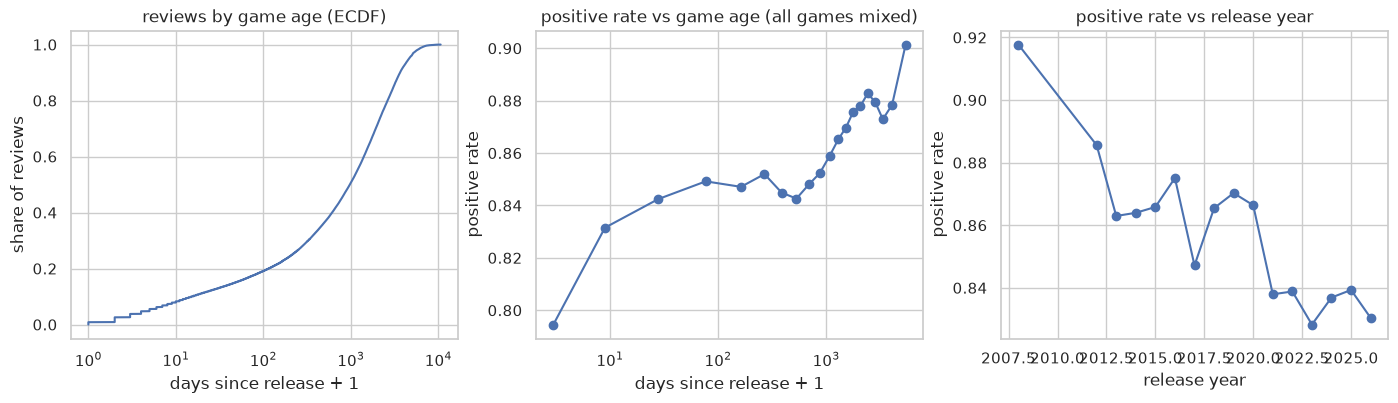

26,255 games with 30+ reviews in both their first 90 days and after: late − early positive rate: mean -0.053, median -0.040, 74% of games get worse


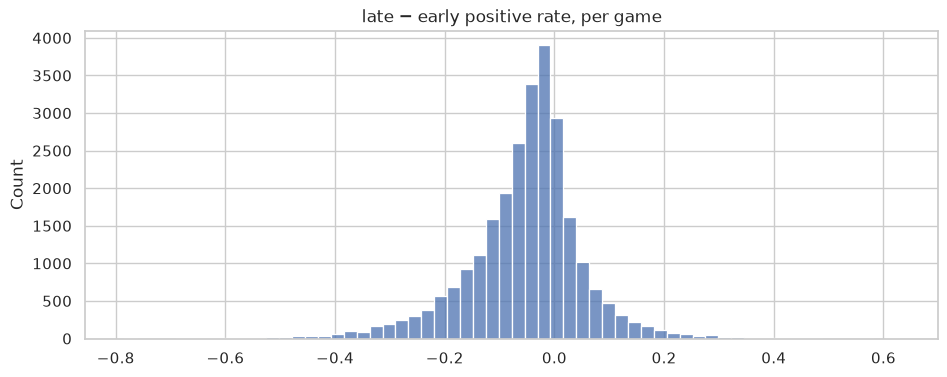

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
x = np.sort(ages.to_numpy()) + 1
axes[0].plot(x, np.arange(1, len(x) + 1) / len(x))
axes[0].set_xscale("log")
axes[0].set(
    title="reviews by game age (ECDF)", xlabel="days since release + 1", ylabel="share of reviews"
)
b = binned_mean(known.filter(pl.col("age_days") >= 0), "age_days", "is_positive", bins=20)
axes[1].plot(b["x"] + 1, b["mean"], marker="o")
axes[1].set_xscale("log")
axes[1].set(
    title="positive rate vs game age (all games mixed)",
    xlabel="days since release + 1",
    ylabel="positive rate",
)
b = binned_mean(r3.filter(pl.col("release_year") >= 2000), "release_year", "is_positive", bins=25)
axes[2].plot(b["x"], b["mean"], marker="o")
axes[2].set(title="positive rate vs release year", xlabel="release year", ylabel="positive rate")
plt.show()

EARLY_DAYS = 90
within = cached(
    f"early_late_{EARLY_DAYS}",
    lambda: (
        scan("reviews")
        .select("game_id", "is_positive", "reviewed_at")
        .join(release.lazy().filter(pl.col("release_date").is_not_null()), on="game_id")
        .with_columns(
            early=(pl.col("reviewed_at").dt.date() - pl.col("release_date")).dt.total_days()
            <= EARLY_DAYS
        )
        .group_by("game_id", "early")
        .agg(n=pl.len(), pos=pl.col("is_positive").mean())
        .collect(engine="streaming")
    ),
)
paired = (
    within.filter(pl.col("n") >= 30)
    .pivot(on="early", index="game_id", values="pos")
    .rename({"true": "early_rate", "false": "late_rate"})
    .drop_nulls()
    .with_columns(diff=pl.col("late_rate") - pl.col("early_rate"))
)
print(
    f"{paired.height:,d} games with 30+ reviews in both their first {EARLY_DAYS} days and after: "
    f"late − early positive rate: mean {paired['diff'].mean():+.3f}, median {paired['diff'].median():+.3f}, "
    f"{(paired['diff'] < 0).mean():.0%} of games get worse"
)
sns.histplot(paired["diff"].to_numpy(), bins=60).set(title="late − early positive rate, per game")
plt.show()

In [11]:
first_year = float((ages <= 365).mean())
note(
    "Q3 game age",
    f"{first_year:.0%} of reviews come in a game's first year vs {expected_first_year:.0%} if spread evenly over "
    f"its life ({float((ages <= 30).mean()):.0%} in the first 30 days); within a game, late − early positive "
    f"rate = {paired['diff'].mean():+.3f}",
    (
        "Age drives **volume** far more than sentiment: add game age at the time of the "
        "recommendation (log days since release, time-varying, so computed as of t) as an item "
        "feature, plus a recent-popularity feature (E3)."
        if first_year > 1.5 * expected_first_year
        else "Reviews spread over a game's life: age is a minor item feature."
    )
    + (
        f" Sentiment does shift with age ({paired['diff'].mean():+.3f}), so the ranker can use it too."
        if abs(paired["diff"].mean()) > 0.02
        else " Positive rates barely move with age."
    ),
)

**Q3 game age** · 32% of reviews come in a game's first year vs 23% if spread evenly over its life (13% in the first 30 days); within a game, late − early positive rate = -0.053

→ Reviews spread over a game's life: age is a minor item feature. Sentiment does shift with age (-0.053), so the ranker can use it too.

## Q4 · Price vs number of reviews and popularity

Released games, by price band (current price; free = `is_free` or price 0). Popularity is the
lifetime review count from every review. On the user side: do users lean towards free or paid
games more than their shuffled twins? Then price is a user preference, not only an item attribute.

In [12]:
cat = games.filter(pl.col("released") & (pl.col("is_free") | pl.col("game_price").is_not_null()))
band = (
    pl.when(pl.col("is_free"))
    .then(pl.lit("0 free"))
    .when(pl.col("game_price") < 5)
    .then(pl.lit("1 <5"))
    .when(pl.col("game_price") < 10)
    .then(pl.lit("2 5-10"))
    .when(pl.col("game_price") < 20)
    .then(pl.lit("3 10-20"))
    .when(pl.col("game_price") < 40)
    .then(pl.lit("4 20-40"))
    .otherwise(pl.lit("5 40+"))
)
cat = cat.with_columns(price_band=band)
q4 = (
    cat.group_by("price_band")
    .agg(
        games=pl.len(),
        reviews=pl.col("reviews").sum(),
        median_reviews=pl.col("reviews").median(),
        mean_reviews=pl.col("reviews").mean(),
        share_with_reviews=(pl.col("reviews") > 0).mean(),
        positive_rate=pl.col("positives").sum() / pl.col("reviews").sum(),
    )
    .with_columns(
        share_of_catalog=pl.col("games") / pl.col("games").sum(),
        share_of_reviews=pl.col("reviews") / pl.col("reviews").sum(),
    )
    .sort("price_band")
)
q4

price_band,games,reviews,median_reviews,mean_reviews,share_with_reviews,positive_rate,share_of_catalog,share_of_reviews
str,u32,u32,f64,f64,f64,f64,f64,f64
"""0 free""",18415,19178324,35.0,1041.451208,0.995982,0.7925,0.142318,0.159885
"""1 <5""",56665,13080967,10.0,230.847384,0.907209,0.849377,0.437929,0.109053
"""2 5-10""",29651,19465764,19.0,656.496037,0.927895,0.883285,0.229155,0.162281
"""3 10-20""",19044,31898601,63.0,1674.994802,0.960197,0.882345,0.14718,0.26593
"""4 20-40""",4455,27362336,297.0,6141.938496,0.968575,0.866387,0.03443,0.228112
"""5 40+""",1163,8965102,33.0,7708.600172,0.904557,0.841083,0.008988,0.07474


paid games with 10+ reviews: Spearman(price, reviews) = +0.319
free games: 14.2% of the catalog, 15.3% of the top 1% by reviews
Gini of reviews per game: 0.955


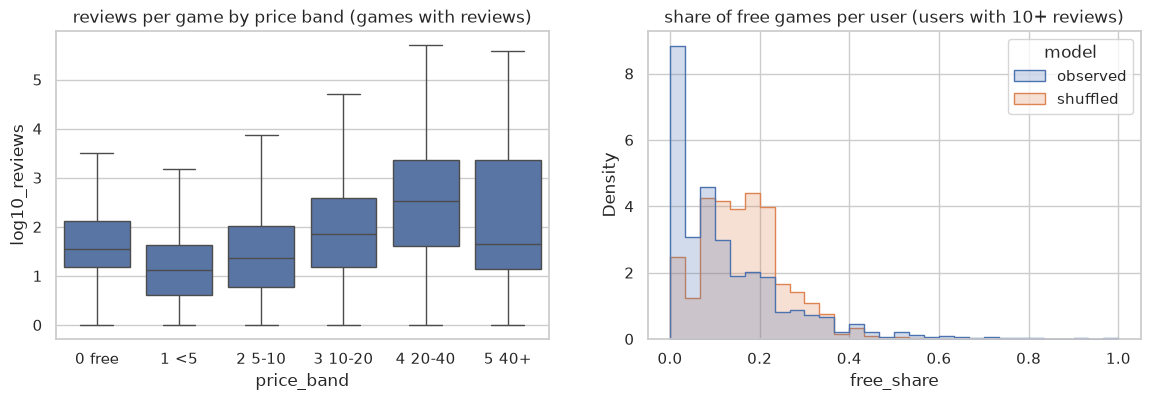

model,free_share
str,f64
"""observed""",0.134349
"""shuffled""",0.092301


In [13]:
paid = cat.filter(~pl.col("is_free") & (pl.col("reviews") >= 10))
rho_price = spearman(paid["game_price"], paid["reviews"].cast(pl.Float64))
top = cat.filter(pl.col("reviews") >= cat["reviews"].quantile(0.99))
print(f"paid games with 10+ reviews: Spearman(price, reviews) = {rho_price:+.3f}")
print(
    f"free games: {cat['is_free'].mean():.1%} of the catalog, {top['is_free'].mean():.1%} of the top 1% by reviews"
)
print(f"Gini of reviews per game: {gini(cat['reviews']):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(
    data=cat.filter(pl.col("reviews") > 0)
    .with_columns(log10_reviews=pl.col("reviews").log10())
    .to_pandas(),
    x="price_band",
    y="log10_reviews",
    order=sorted(q4["price_band"]),
    showfliers=False,
    ax=axes[0],
)
axes[0].set_title("reviews per game by price band (games with reviews)")

user_free = lambda df: (  # noqa: E731
    df.join(cat.select("game_id", "is_free"), on="game_id")
    .group_by("user_id")
    .agg(n=pl.len(), free_share=pl.col("is_free").mean())
    .filter(pl.col("n") >= 10)
)
uf = pl.concat(
    [
        user_free(reviews).with_columns(model=pl.lit("observed")),
        user_free(shuffle_games(reviews, SEED)).with_columns(model=pl.lit("shuffled")),
    ]
)
sns.histplot(
    data=uf.to_pandas(),
    x="free_share",
    hue="model",
    stat="density",
    common_norm=False,
    bins=30,
    element="step",
    ax=axes[1],
)
axes[1].set_title("share of free games per user (users with 10+ reviews)")
plt.show()
sd = uf.group_by("model").agg(pl.col("free_share").std()).sort("model")
sd

In [14]:
sd_obs, sd_null = sd["free_share"][0], sd["free_share"][1]
free_lift = float(top["is_free"].mean() / max(cat["is_free"].mean(), 1e-9))
note(
    "Q4 price vs popularity",
    f"free games are {cat['is_free'].mean():.0%} of the catalog but {top['is_free'].mean():.0%} of the top 1% "
    f"(×{free_lift:.1f}); paid: ρ(price, reviews) = {rho_price:+.3f}; spread of users' free share "
    f"{sd_obs:.3f} observed vs {sd_null:.3f} shuffled",
    (
        "Price matters: keep `game_is_free` and add a log-price band item feature. "
        if free_lift > 1.5 or abs(rho_price) > 0.1
        else "Price says little about popularity. "
    )
    + (
        "Users differ in their free / paid lean beyond chance: add the user's free share (as of t) to "
        "the user tower / ranker, or let the price feature interact with the user."
        if sd_obs > 1.3 * sd_null
        else "Users don't lean free / paid beyond chance."
    ),
)

**Q4 price vs popularity** · free games are 14% of the catalog but 15% of the top 1% (×1.1); paid: ρ(price, reviews) = +0.319; spread of users' free share 0.134 observed vs 0.092 shuffled

→ Price matters: keep `game_is_free` and add a log-price band item feature. Users differ in their free / paid lean beyond chance: add the user's free share (as of t) to the user tower / ranker, or let the price feature interact with the user.

## Q5 · Does the order of the recent history matter?

For users with more than 20 reviews: the mean tag Jaccard between review *t* and review *t − k*,
k = 1..20, over the same targets for every k. If the curve decays with k, the latest games say
more about the next one than older ones, and order matters (recency weighting, a sequence model /
attention with positions). If it's flat, and the same as the shuffled-order null, a bag of games
(mean pooling) is as good. One caveat first: many users review in bursts (several games in
minutes), and inside a burst the order is arbitrary.

31,185 users with >20 reviews (1,321,679 reviews); consecutive reviews within 1 minute: 4%, same day: 22%


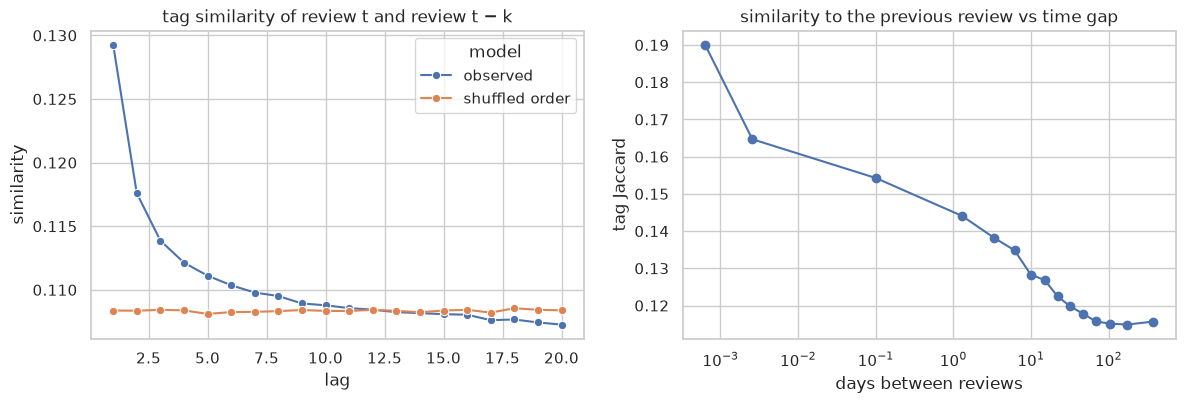

In [15]:
LAG = 20
seq_users = activity.filter(pl.col("n") > LAG)
r5 = reviews.join(seq_users, on="user_id", how="semi")
pairs = consecutive_pairs(r5, TAGS, "tags")
print(
    f"{seq_users.height:,d} users with >{LAG} reviews ({r5.height:,d} reviews); consecutive reviews "
    f"within 1 minute: {(pairs['gap_days'] < 1 / 1440).mean():.0%}, same day: {(pairs['gap_days'] < 1).mean():.0%}"
)

lags = pl.concat(
    [
        lag_similarity(r5, TAGS, "tags", LAG).with_columns(model=pl.lit("observed")),
        lag_similarity(shuffle_order(r5, SEED), TAGS, "tags", LAG).with_columns(
            model=pl.lit("shuffled order")
        ),
    ]
)
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.lineplot(data=lags.to_pandas(), x="lag", y="similarity", hue="model", marker="o", ax=axes[0])
axes[0].set_title("tag similarity of review t and review t − k")
b = binned_mean(pairs, "gap_days", "similarity", bins=15)
axes[1].plot(b["x"] + 1e-4, b["mean"], marker="o")
axes[1].set_xscale("log")
axes[1].set(
    title="similarity to the previous review vs time gap",
    xlabel="days between reviews",
    ylabel="tag Jaccard",
)
plt.show()

In [16]:
obs = lags.filter(pl.col("model") == "observed")
null_sim = lags.filter(pl.col("model") == "shuffled order")["similarity"].mean()
lag1, lagn = obs["similarity"][0], obs["similarity"][-1]
decay = (lag1 - lagn) / lagn
note(
    "Q5 order of the history",
    f"tag similarity to the previous review {lag1:.3f} vs {lagn:.3f} at lag {LAG} ({decay:+.0%}); "
    f"shuffled order {null_sim:.3f}",
    (
        "Order matters: recent games predict the next one better than older ones. Worth a sequence "
        "user tower (self-attention with positions / recency) or at least recency-weighted pooling, "
        "with time gaps as an input: bursts are near-duplicates in time."
        if decay > 0.1
        else "Little decay: the history behaves like a set. Mean pooling (current tower) is enough; "
        "spend the effort on longer histories, not on order."
    ),
)

**Q5 order of the history** · tag similarity to the previous review 0.129 vs 0.107 at lag 20 (+21%); shuffled order 0.108

→ Order matters: recent games predict the next one better than older ones. Worth a sequence user tower (self-attention with positions / recency) or at least recency-weighted pooling, with time gaps as an input: bursts are near-duplicates in time.

## Q6 · Do description embeddings group games with a similar premise?

Short descriptions of the most reviewed released games, embedded with MiniLM (`all-MiniLM-L6-v2`,
when the `nlp` group is installed) and TF-IDF + SVD (lexical baseline). Three checks:

- **a. Neighbours share tags?** Tag Jaccard of each game with its 10 nearest neighbours vs random pairs.
- **b. Beyond tags?** The decisive one: pairs of games liked by the same user vs popularity-matched
  random pairs. Is embedding similarity predictive *on top of* tag / genre overlap (cross-validated
  logistic regression)? If it is, the embedding carries something the item tower lacks.
- **c. Clusters.** K-means clusters with their top tags, and a 2-D map.

In [17]:
N_EMBED = 30_000
emb_games = (
    games.filter(pl.col("released") & (pl.col("game_short_description").str.len_chars() >= 30))
    .sort("reviews", descending=True)
    .head(N_EMBED)
    .select("game_id", "game_name", "game_short_description", "reviews", "tag_names", "game_genres")
)
METHOD = "minilm" if S.text_models == "auto" and nlp.has_nlp() else "tfidf"
texts = emb_games["game_short_description"].to_list()
emb_df = cached(
    f"desc_emb_{METHOD}_{emb_games.height}",
    lambda: pl.DataFrame(
        {"game_id": emb_games["game_id"], "emb": nlp.embed_texts(texts, method=METHOD)[0].tolist()}
    ),
)
EMB = np.asarray(emb_df["emb"].to_list(), dtype=np.float32)
LEX = nlp.tfidf_embed(texts) if METHOD != "tfidf" else EMB
row = {g: i for i, g in enumerate(emb_games["game_id"].to_list())}
print(
    f"{emb_games.height:,d} games embedded with {METHOD}"
    + ("" if METHOD == "minilm" else " (install the nlp group, `uv sync --group nlp`, for MiniLM)")
)

/home/sadelcarpio/code/steam-recsys-e2e/notebooks/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


30,000 games embedded with minilm


In [18]:
rng = np.random.default_rng(SEED)
k = 10
idx = {name: nlp.knn(m, k) for name, m in [(METHOD, EMB), ("tfidf", LEX)]}
gid = emb_games["game_id"].to_numpy()
neigh_pairs = [
    pl.DataFrame({"a": np.repeat(gid, k), "b": gid[nn.ravel()], "pairs": name})
    for name, nn in idx.items()
] + [pl.DataFrame({"a": gid, "b": gid[rng.permutation(len(gid))], "pairs": "random"})]
tag_of = emb_games.select(
    "game_id", t=pl.col("tag_names").list.head(TOP_TAGS_PER_GAME).fill_null([])
)
nbr = (
    pl.concat(neigh_pairs)
    .unique(["a", "b", "pairs"])
    .join(tag_of.rename({"game_id": "a", "t": "ta"}), on="a")
    .join(tag_of.rename({"game_id": "b", "t": "tb"}), on="b")
    .with_columns(tag_jaccard=jaccard(pl.col("ta"), pl.col("tb")))
    .group_by("pairs")
    .agg(mean_tag_jaccard=pl.col("tag_jaccard").mean(), n=pl.len())
    .sort("mean_tag_jaccard", descending=True)
)
nbr

pairs,mean_tag_jaccard,n
str,f64,u32
"""minilm""",0.163249,300000
"""tfidf""",0.147806,300000
"""random""",0.061247,30000


In [19]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# b. pairs of games positively reviewed by the same user (consecutive in a random order) vs pairs
# with a popularity-sampled random partner
liked = (
    reviews.filter(pl.col("is_positive") & pl.col("game_id").is_in(list(row)))
    .select("user_id", "game_id")
    .with_columns(
        _r=pl.Series(
            rng.random(
                reviews.filter(pl.col("is_positive") & pl.col("game_id").is_in(list(row))).height
            )
        )
    )
    .sort("user_id", "_r")
    .with_columns(b=pl.col("game_id").shift(-1).over("user_id"))
    .drop_nulls("b")
    .filter(pl.col("game_id") != pl.col("b"))
    .rename({"game_id": "a"})
    .select("a", "b")
)
liked = liked.sample(min(liked.height, 200_000), seed=SEED)
weights = emb_games["reviews"].to_numpy().astype(float)
rand_b = rng.choice(gid, size=liked.height, p=weights / weights.sum())
pairs6 = pl.concat(
    [
        liked.with_columns(label=pl.lit(1)),
        liked.select("a").with_columns(b=pl.Series(rand_b), label=pl.lit(0)),
    ]
).filter(pl.col("a") != pl.col("b"))
ia = np.array([row[g] for g in pairs6["a"]])
ib = np.array([row[g] for g in pairs6["b"]])
genre_of = emb_games.select("game_id", g=pl.col("game_genres").fill_null([]))
pairs6 = (
    pairs6.with_columns(
        emb_cos=pl.Series((EMB[ia] * EMB[ib]).sum(1)),
        lex_cos=pl.Series((LEX[ia] * LEX[ib]).sum(1)),
        log_pop_b=pl.Series(np.log1p(weights[ib])),
    )
    .join(tag_of.rename({"game_id": "a", "t": "ta"}), on="a")
    .join(tag_of.rename({"game_id": "b", "t": "tb"}), on="b")
    .join(genre_of.rename({"game_id": "a", "g": "ga"}), on="a")
    .join(genre_of.rename({"game_id": "b", "g": "gb"}), on="b")
    .with_columns(
        tag_jaccard=jaccard(pl.col("ta"), pl.col("tb")).fill_null(0),
        genre_jaccard=jaccard(pl.col("ga"), pl.col("gb")).fill_null(0),
    )
)
single = pl.DataFrame(
    [
        {"feature": f, "auc": auc(pairs6["label"], pairs6[f])}
        for f in ["tag_jaccard", "genre_jaccard", "emb_cos", "lex_cos", "log_pop_b"]
    ]
)
y = pairs6["label"].to_numpy()


def cv_auc(cols: list[str]) -> float:
    X = pairs6.select(cols).to_numpy()
    return float(
        cross_val_score(LogisticRegression(max_iter=1000), X, y, cv=5, scoring="roc_auc").mean()
    )


base_cols = ["tag_jaccard", "genre_jaccard", "log_pop_b"]
combo = pl.DataFrame(
    [
        {"model": "tags + genres + popularity", "cv_auc": cv_auc(base_cols)},
        {"model": f"+ {METHOD} description cosine", "cv_auc": cv_auc(base_cols + ["emb_cos"])},
    ]
    + (
        [{"model": "+ tfidf description cosine", "cv_auc": cv_auc(base_cols + ["lex_cos"])}]
        if METHOD != "tfidf"
        else []
    )
)
print(f"{pairs6.height:,d} pairs")
display(single)
combo

399,819 pairs


feature,auc
str,f64
"""tag_jaccard""",0.612812
"""genre_jaccard""",0.583496
"""emb_cos""",0.558605
"""lex_cos""",0.554461
"""log_pop_b""",0.480569


model,cv_auc
str,f64
"""tags + genres + popularity""",0.623288
"""+ minilm description cosine""",0.626629
"""+ tfidf description cosine""",0.625019


mean tag Jaccard within a cluster 0.099 vs random pairs 0.061


cluster,games,distinctive_tags,examples
i32,u32,list[str],list[str]
34,1297,"[""Tanks"", ""Sniper"", … ""On-Rails Shooter""]","[""Tom Clancy's Rainbow Six Siege"", ""Team Fortress 2"", … ""PUBG: BATTLEGROUNDS""]"
25,1286,"[""Dragons"", ""MMORPG"", … ""CRPG""]","[""Valheim"", ""Hollow Knight: Silksong"", … ""Hogwarts Legacy""]"
14,1277,"[""Billiards"", ""Golf"", … ""Board Game""]","[""Warframe"", ""Satisfactory"", … ""Sid Meier's Civilization® V""]"
18,1124,"[""Roguelike Deckbuilder"", ""Bullet Heaven"", … ""Action Roguelike""]","[""Hades"", ""Slay the Spire"", … ""Persona 5 Royal""]"
4,1048,"[""Pinball"", ""Rhythm"", … ""Gambling""]","[""Cuphead"", ""Hotline Miami"", … ""Banana""]"
5,1034,"[""Survival Horror"", ""Horror"", … ""Psychological""]","[""R.E.P.O."", ""Undertale"", … ""Getting Over It with Bennett Foddy""]"
13,1005,"[""Mythology"", ""Villain Protagonist"", … ""Souls-like""]","[""Sid Meier’s Civilization® VI"", ""The Witcher 3: Wild Hunt - Complete Edition"", … ""Mount & Blade: Warband""]"
2,926,"[""Romance"", ""Dating Sim"", … ""Visual Novel""]","[""LoveChoice"", ""Doki Doki Literature Club Plus!"", … ""My Friend Pedro""]"
15,923,"[""Space Sim"", ""Space"", … ""Aliens""]","[""Don't Starve Together"", ""Deep Rock Galactic"", … ""Stellaris""]"


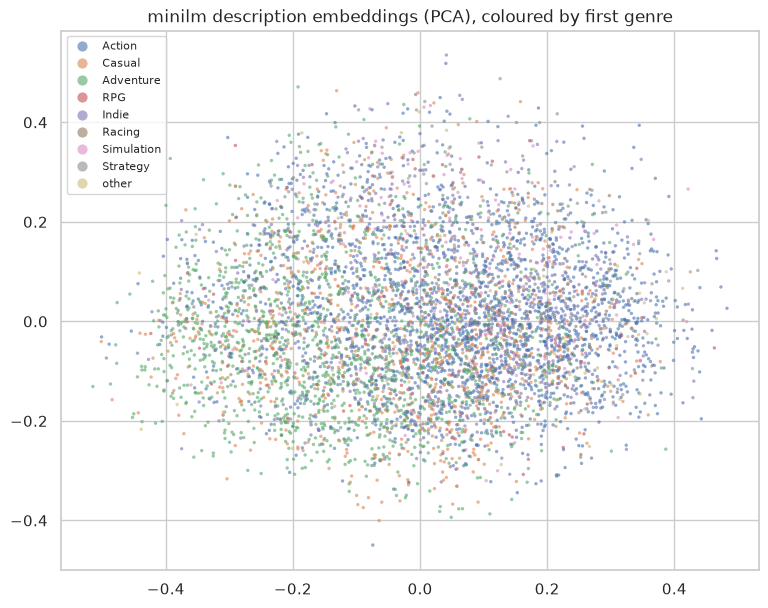

In [20]:
from sklearn.cluster import MiniBatchKMeans
from sklearn.decomposition import PCA

N_CLUSTERS = 40 if emb_games.height > 2000 else 5
clusters = MiniBatchKMeans(N_CLUSTERS, random_state=SEED, n_init=3).fit_predict(EMB)
cl = emb_games.with_columns(cluster=pl.Series(clusters))
# the tags that set a cluster apart: share of the cluster's games with the tag / share in all games
cl_tags = (
    cl.select("cluster", t=pl.col("tag_names").list.head(5).fill_null([]))
    .explode("t")
    .drop_nulls("t")
)
tag_share = cl_tags.group_by("t").agg(overall=pl.len() / cl.height)
distinctive = (
    cl_tags.group_by("cluster", "t")
    .agg(c=pl.len())
    .join(cl.group_by("cluster").agg(size=pl.len()), on="cluster")
    .join(tag_share, on="t")
    .filter(pl.col("c") >= 10)
    .with_columns(lift=(pl.col("c") / pl.col("size")) / pl.col("overall"))
    .sort("lift", descending=True)
    .group_by("cluster", maintain_order=True)
    .agg(distinctive_tags=pl.col("t").head(5))
)
cluster_table = (
    cl.group_by("cluster")
    .agg(games=pl.len(), examples=pl.col("game_name").sort_by("reviews", descending=True).head(4))
    .join(distinctive, on="cluster", how="left")
    .sort("games", descending=True)
    .select("cluster", "games", "distinctive_tags", "examples")
)
within = (
    cl.select("game_id", "cluster")
    .join(cl.select("game_id", "cluster").rename({"game_id": "b"}), on="cluster")
    .filter(pl.col("game_id") < pl.col("b"))
    .sample(fraction=1.0, shuffle=True, seed=SEED)
    .head(300_000)
    .join(tag_of.rename({"t": "ta"}), on="game_id")
    .join(tag_of.rename({"game_id": "b", "t": "tb"}), on="b")
    .select(jaccard(pl.col("ta"), pl.col("tb")).mean())
    .item()
)
print(
    f"mean tag Jaccard within a cluster {within:.3f} vs random pairs "
    f"{nbr.filter(pl.col('pairs') == 'random')['mean_tag_jaccard'][0]:.3f}"
)
display(cluster_table.head(20))

sub = rng.choice(len(EMB), size=min(6000, len(EMB)), replace=False)
xy = PCA(2, random_state=SEED).fit_transform(EMB[sub])
genre1 = cl[sub.tolist()].select(g=pl.col("game_genres").list.first().fill_null("?"))["g"]
top_genres = genre1.value_counts(sort=True).head(8)["g"].to_list()
plt.figure(figsize=(9, 7))
sns.scatterplot(
    x=xy[:, 0],
    y=xy[:, 1],
    hue=[g if g in top_genres else "other" for g in genre1],
    s=6,
    alpha=0.6,
    linewidth=0,
)
plt.title(f"{METHOD} description embeddings (PCA), coloured by first genre")
plt.legend(markerscale=3, fontsize=8)
plt.show()

In [21]:
base_auc = combo["cv_auc"][0]
gain = combo["cv_auc"][1] - base_auc
nb = {r["pairs"]: r["mean_tag_jaccard"] for r in nbr.iter_rows(named=True)}
note(
    "Q6 description embeddings",
    f"10-NN tag Jaccard {nb[METHOD]:.3f} ({METHOD}) vs {nb['random']:.3f} random; co-liked pairs: "
    f"tags+genres+popularity AUC {base_auc:.3f}, + description cosine {combo['cv_auc'][1]:.3f} ({gain:+.3f})",
    (
        "Embeddings group games by premise and add signal beyond tags: add a frozen, precomputed "
        "description embedding to the item tower. It matters most for cold-start games with few reviews."
        if gain > 0.01
        else "Embeddings mostly rediscover the tags (neighbours share tags), but add little beyond them for "
        "what users like together. Tags first; the embedding is only worth it for games with few tags."
    ),
)

**Q6 description embeddings** · 10-NN tag Jaccard 0.163 (minilm) vs 0.061 random; co-liked pairs: tags+genres+popularity AUC 0.623, + description cosine 0.627 (+0.003)

→ Embeddings mostly rediscover the tags (neighbours share tags), but add little beyond them for what users like together. Tags first; the embedding is only worth it for games with few tags.

## Q7 · Are negative reviews an important signal?

The user history (`games_reviewed_positive`) holds positives only, but the retrieval loss uses one
negatively reviewed game per example as an **explicit hard negative** (`EXPLICIT_NEGATIVES`, on by
default), next to in-batch (logQ-corrected) and mined negatives. That bets that a negative review
means "not for me". The alternative: a negative review is still an interaction, a game the user
was drawn to, so for *retrieval* (what will the user engage with) it marks interest, and the
like / dislike call belongs to the ranker. Checks, for users with 5+ reviews:

- how common negatives are, and how they're spread over users;
- **fit** of the reviewed game with the user's *positive* history (leave-one-out): positives vs
  negatives vs popularity-sampled random games. Negatives close to positives and far above random
  mean they're about games the user was interested in;
- playtime at review of negatives (did they play before disliking?);
- after a negative, does the next game move away from it (avoidance) or stay close (interest)?
- label-quality flags (free copies, early access).

In [22]:
r7 = reviews.join(eval_users, on="user_id", how="semi")
pos_hist = r7.filter(pl.col("is_positive"))
pool = games.filter(
    pl.col("released") & (pl.col("reviews") > 0) & (pl.col("tag_names").list.len() > 0)
)
w = pool["reviews"].to_numpy().astype(float)
random_rows = r7.select("user_id", review_id=-pl.col("review_id")).with_columns(
    game_id=pl.Series(rng.choice(pool["game_id"].to_numpy(), size=r7.height, p=w / w.sum()))
)
fit7 = pl.concat(
    [
        r7.join(profile_fit(pos_hist, r7, TAGS, "tags"), on="review_id").select(
            "fit",
            kind=pl.when(pl.col("is_positive"))
            .then(pl.lit("positive review"))
            .otherwise(pl.lit("negative review")),
        ),
        profile_fit(pos_hist, random_rows, TAGS, "tags").select(
            "fit", kind=pl.lit("random popular game")
        ),
    ]
).drop_nulls()
fit_summary = (
    fit7.group_by("kind")
    .agg(rows=pl.len(), mean_fit=pl.col("fit").mean(), median_fit=pl.col("fit").median())
    .sort("mean_fit", descending=True)
)

neg_rate = r7.group_by("user_id").agg(neg=(~pl.col("is_positive")).mean())
print(
    f"negative reviews: {(~reviews['is_positive']).mean():.1%} overall; users with 5+ reviews having at least one: "
    f"{(neg_rate['neg'] > 0).mean():.0%}; median negative share among those: {neg_rate.filter(pl.col('neg') > 0)['neg'].median():.0%}"
)
print(
    "median hours at review:",
    r7.group_by("is_positive")
    .agg((pl.col("playtime_at_review").median() / 60).round(1))
    .sort("is_positive")
    .rows(),
)
fit_summary

negative reviews: 14.3% overall; users with 5+ reviews having at least one: 54%; median negative share among those: 20%
median hours at review: [(False, 5.3), (True, 10.9)]


kind,rows,mean_fit,median_fit
str,u32,f64,f64
"""positive review""",2866036,0.193465,0.180645
"""negative review""",511274,0.186913,0.175
"""random popular game""",3381302,0.129834,0.12


In [23]:
s7 = sequence(r7.select("user_id", "game_id", "reviewed_at", "review_id", "is_positive")).join(
    TAGS, on="game_id", how="left"
)
after = (
    s7.with_columns(
        prev_tags=pl.col("tags").shift(1).over("user_id"),
        prev_positive=pl.col("is_positive").shift(1).over("user_id"),
        gap=(
            pl.col("reviewed_at") - pl.col("reviewed_at").shift(1).over("user_id")
        ).dt.total_seconds(),
    )
    .filter(pl.col("prev_positive").is_not_null() & (pl.col("gap") > 3600))  # bursts excluded
    .group_by("prev_positive")
    .agg(next_similarity=jaccard(pl.col("tags"), pl.col("prev_tags")).mean(), pairs=pl.len())
)
display(after)
flags = (
    pl.concat(
        [
            reviews.group_by(f)
            .agg(rows=pl.len(), positive_rate=pl.col("is_positive").mean())
            .rename({f: "value"})
            .with_columns(pl.col("value").cast(pl.String), flag=pl.lit(f))
            for f in [
                "received_for_free",
                "steam_purchase",
                "written_during_early_access",
                "primarily_steam_deck",
            ]
        ]
    )
    .select("flag", "value", "rows", "positive_rate")
    .sort("flag", "value")
)
flags

prev_positive,next_similarity,pairs
bool,f64,u32
false,0.123379,424879
true,0.127861,2339302


flag,value,rows,positive_rate
str,str,u32,f64
"""primarily_steam_deck""","""false""",5972529,0.857149
"""primarily_steam_deck""","""true""",42338,0.865133
"""received_for_free""","""false""",5813147,0.857762
"""received_for_free""","""true""",201720,0.841146
"""steam_purchase""","""false""",1009038,0.84722
"""steam_purchase""","""true""",5005829,0.859218
"""written_during_early_access""","""false""",5334889,0.859175
"""written_during_early_access""","""true""",679978,0.841754


In [24]:
fs = {r["kind"]: r["mean_fit"] for r in fit_summary.iter_rows(named=True)}
next_after_neg = after.filter(~pl.col("prev_positive"))["next_similarity"][0]
next_after_pos = after.filter(pl.col("prev_positive"))["next_similarity"][0]
gap_to_random = (fs["negative review"] - fs["random popular game"]) / max(
    fs["positive review"] - fs["random popular game"], 1e-9
)
note(
    "Q7 negative reviews",
    f"{(~reviews['is_positive']).mean():.0%} of reviews; fit with the positive history: positive {fs['positive review']:.3f}, "
    f"negative {fs['negative review']:.3f}, random {fs['random popular game']:.3f} (negatives sit {gap_to_random:.0%} of "
    f"the way from random to positive); next game's similarity after a negative {next_after_neg:.3f} vs after a "
    f"positive {next_after_pos:.3f}",
    (
        "Negatives mark interest: they sit in the user's own taste region and users don't move away after "
        "one. As retrieval hard negatives they push the user away from tag-similar games they'd like (the "
        "towers can only tell them apart by game id). Proposal: drop them as explicit retrieval negatives "
        "(or count them as low-weight interactions) and use them as label 0 in the ranker. Confirm with "
        "an EXPLICIT_NEGATIVES=false ablation on warm recall@50."
        if gap_to_random > 0.5 and next_after_neg > 0.8 * next_after_pos
        else "Negatives sit away from the user's taste or push the next pick away: they behave like real "
        "'not for me' signals, so keeping them as explicit retrieval hard negatives is justified."
    ),
)

**Q7 negative reviews** · 14% of reviews; fit with the positive history: positive 0.193, negative 0.187, random 0.130 (negatives sit 90% of the way from random to positive); next game's similarity after a negative 0.123 vs after a positive 0.128

→ Negatives mark interest: they sit in the user's own taste region and users don't move away after one. As retrieval hard negatives they push the user away from tag-similar games they'd like (the towers can only tell them apart by game id). Proposal: drop them as explicit retrieval negatives (or count them as low-weight interactions) and use them as label 0 in the ranker. Confirm with an EXPLICIT_NEGATIVES=false ablation on warm recall@50.

## Q8 · Sentiment of a game's top reviews as a feature

The label already *is* a sentiment (recommended or not), and the game's positive ratio is already
a feature. So text sentiment helps only if it says something the ratio doesn't. Setup:

- cutoff = snapshot − 180 days; games with 50+ reviews before and 30+ after;
- per game, the `TOP_N` most helpful English reviews before the cutoff (`weighted_vote_score`), scored
  by an SST-2 classifier (P(positive));
- target: the game's positive ratio **after** the cutoff. Does mean text sentiment improve on the
  ratio before the cutoff (cross-validated R²)?

Needs the `nlp` group (otherwise this section only reports that it was skipped). The texts are
read from every review file once, then cached.

In [25]:
from sklearn.linear_model import LinearRegression

CUTOFF = SNAPSHOT - timedelta(days=180)
N_SENT_GAMES, TOP_N = 1500, 10
periods = cached(
    f"periods_{CUTOFF:%Y%m%d}",
    lambda: (
        scan("reviews")
        .group_by("game_id")
        .agg(
            n_before=(pl.col("reviewed_at") < CUTOFF).sum(),
            pos_before=((pl.col("reviewed_at") < CUTOFF) & pl.col("is_positive")).sum(),
            n_after=(pl.col("reviewed_at") >= CUTOFF).sum(),
            pos_after=((pl.col("reviewed_at") >= CUTOFF) & pl.col("is_positive")).sum(),
        )
        .collect(engine="streaming")
    ),
)
chosen = periods.filter((pl.col("n_before") >= 50) & (pl.col("n_after") >= 30))
chosen = chosen.sample(min(N_SENT_GAMES, chosen.height), seed=SEED)
sent = None
if S.text_models == "auto" and nlp.has_nlp():
    ids = chosen["game_id"].to_list()
    top_reviews = cached(
        f"top_reviews_{CUTOFF:%Y%m%d}_{chosen.height}_{TOP_N}",
        lambda: (
            scan("reviews")
            .filter(
                pl.col("game_id").is_in(ids)
                & (pl.col("language") == "english")
                & (pl.col("reviewed_at") < CUTOFF)
            )
            .select(
                "game_id", "review_id", "is_positive", "weighted_vote_score", "votes_up", "review"
            )
            .filter(pl.col("review").str.len_chars() >= 20)
            .collect(engine="streaming")
            .sort("weighted_vote_score", "votes_up", descending=True)
            .group_by("game_id", maintain_order=True)
            .head(TOP_N)
        ),
    )
    sent = cached(
        f"sentiment_{CUTOFF:%Y%m%d}_{chosen.height}_{TOP_N}",
        lambda: top_reviews.select("game_id", "review_id", "is_positive").with_columns(
            p_text=pl.Series(nlp.sentiment(top_reviews["review"].to_list()))
        ),
    )
    print(f"{sent.height:,d} top reviews of {sent['game_id'].n_unique():,d} games scored")
else:
    print("skipped: needs the nlp group (`uv sync --group nlp`) and EDA_TEXT_MODELS=auto")

14,819 top reviews of 1,499 games scored


In [26]:
if sent is None:
    note(
        "Q8 sentiment of top reviews",
        "not run (no text models)",
        "Run with the nlp group to answer.",
    )
else:
    review_auc = auc(sent["is_positive"], sent["p_text"])
    disagree = float(((sent["p_text"] > 0.5) != sent["is_positive"]).mean())
    g8 = (
        sent.group_by("game_id")
        .agg(
            text_sentiment=pl.col("p_text").mean(), top_positive_share=pl.col("is_positive").mean()
        )
        .join(chosen, on="game_id")
        .with_columns(
            ratio_before=smoothed_ratio(pl.col("pos_before"), pl.col("n_before")),
            ratio_after=smoothed_ratio(pl.col("pos_after"), pl.col("n_after")),
        )
    )
    yy = g8["ratio_after"].to_numpy()

    def r2(cols):
        return float(
            cross_val_score(
                LinearRegression(), g8.select(cols).to_numpy(), yy, cv=5, scoring="r2"
            ).mean()
        )

    q8 = pl.DataFrame(
        [
            {"model": "ratio before", "cv_r2": r2(["ratio_before"])},
            {
                "model": "+ top-review positive share",
                "cv_r2": r2(["ratio_before", "top_positive_share"]),
            },
            {
                "model": "+ top-review text sentiment",
                "cv_r2": r2(["ratio_before", "text_sentiment"]),
            },
        ]
    )
    display(q8)
    print(
        f"review level: AUC of text sentiment for the review's own label {review_auc:.3f}; "
        f"text and label disagree on {disagree:.0%} of top reviews (jokes, sarcasm, 'recommended but…')"
    )
    print(
        f"game level: ρ(text sentiment, ratio before) = {spearman(g8['text_sentiment'], g8['ratio_before']):+.3f}, "
        f"ρ(text sentiment, ratio after) = {spearman(g8['text_sentiment'], g8['ratio_after']):+.3f}"
    )
    gain8 = q8["cv_r2"][2] - q8["cv_r2"][0]
    note(
        "Q8 sentiment of top reviews",
        f"text sentiment vs own label AUC {review_auc:.3f}; future ratio R²: {q8['cv_r2'][0]:.3f} with the past ratio, "
        f"{q8['cv_r2'][2]:.3f} adding text sentiment ({gain8:+.3f})",
        (
            "Text sentiment adds information beyond the ratio: worth a precomputed per-game feature."
            if gain8 > 0.01
            else "Redundant: the review label already is the sentiment and the smoothed ratio captures it. "
            "If review text is used, use it for *what* people talk about (aspects, embeddings of top "
            "reviews, LLM rerank explanations), not for positive vs negative."
        ),
    )

model,cv_r2
str,f64
"""ratio before""",0.685017
"""+ top-review positive share""",0.685181
"""+ top-review text sentiment""",0.685555


review level: AUC of text sentiment for the review's own label 0.875; text and label disagree on 30% of top reviews (jokes, sarcasm, 'recommended but…')
game level: ρ(text sentiment, ratio before) = +0.584, ρ(text sentiment, ratio after) = +0.497


**Q8 sentiment of top reviews** · text sentiment vs own label AUC 0.875; future ratio R²: 0.685 with the past ratio, 0.686 adding text sentiment (+0.001)

→ Redundant: the review label already is the sentiment and the smoothed ratio captures it. If review text is used, use it for *what* people talk about (aspects, embeddings of top reviews, LLM rerank explanations), not for positive vs negative.

## E2 · Developer loyalty

Share of a user's reviews (users with 5+) whose developer they had already reviewed before, vs
the same users with shuffled games.

In [27]:
def repeat_developer(df: pl.DataFrame) -> float:
    s = (
        sequence(df.select("user_id", "game_id", "reviewed_at", "review_id"))
        .join(DEVELOPERS, on="game_id", how="left")
        .explode("developers")
        .drop_nulls("developers")
        .with_columns(seen=pl.col("pos").min().over("user_id", "developers") < pl.col("pos"))
        .group_by("review_id")
        .agg(pl.col("seen").any())
    )
    return float(s["seen"].mean())


r_e2 = reviews.join(eval_users, on="user_id", how="semi")
obs_rep, null_rep = repeat_developer(r_e2), repeat_developer(shuffle_games(r_e2, SEED))
note(
    "E2 developer loyalty",
    f"{obs_rep:.1%} of reviews are of a developer the user reviewed before, vs {null_rep:.1%} shuffled (×{obs_rep / max(null_rep, 1e-9):.1f})",
    "Developers repeat beyond popularity: keep the developer ids in the item tower and add a "
    "'developer already in history' ranker feature."
    if obs_rep > 1.5 * null_rep
    else "Little loyalty beyond popularity: developer ids are a minor item feature.",
)

**E2 developer loyalty** · 9.5% of reviews are of a developer the user reviewed before, vs 3.3% shuffled (×2.8)

→ Developers repeat beyond popularity: keep the developer ids in the item tower and add a 'developer already in history' ranker feature.

## E3 · Is popularity stable over time?

Reviews per game in the last 90 days vs the 90 days before (every review). If the ranking of games
reshuffles fast, a lifetime popularity count (or the training-time popularity in the towers' logQ
correction) is stale, and a recent-window popularity feature is needed.

In [28]:
w1, w2 = SNAPSHOT - timedelta(days=180), SNAPSHOT - timedelta(days=90)
win = cached(
    f"windows_{w2:%Y%m%d}",
    lambda: (
        scan("reviews")
        .filter(pl.col("reviewed_at") >= w1)
        .group_by("game_id")
        .agg(
            prev_90d=(pl.col("reviewed_at") < w2).sum(),
            last_90d=(pl.col("reviewed_at") >= w2).sum(),
        )
        .collect(engine="streaming")
    ),
).join(games.select("game_id", "release_date", "reviews"), on="game_id", how="left")
rho_win = spearman(win["prev_90d"].cast(pl.Float64), win["last_90d"].cast(pl.Float64))
top100 = lambda c: set(win.sort(c, descending=True).head(100)["game_id"].to_list())  # noqa: E731
overlap = len(top100("prev_90d") & top100("last_90d")) / 100
rho_life = spearman(win["reviews"].cast(pl.Float64), win["last_90d"].cast(pl.Float64))
new_share = float(
    win.filter(pl.col("release_date") >= (SNAPSHOT - timedelta(days=365)).date())["last_90d"].sum()
    / win["last_90d"].sum()
)
note(
    "E3 popularity over time",
    f"ρ(reviews prev 90d, last 90d) = {rho_win:+.3f}, top-100 overlap {overlap:.0%}; ρ(lifetime, last 90d) = {rho_life:+.3f}; "
    f"{new_share:.0%} of the last 90 days' reviews go to games released in the last year",
    "Popularity moves fast and new games take a big share: add a recent-window popularity item "
    "feature (e.g. log reviews in the last 30 / 90 days as of t) next to the lifetime one."
    if overlap < 0.7 or new_share > 0.3
    else "Popularity is fairly stable: the lifetime count is a fine proxy.",
)

**E3 popularity over time** · ρ(reviews prev 90d, last 90d) = +0.519, top-100 overlap 62%; ρ(lifetime, last 90d) = +0.643; 31% of the last 90 days' reviews go to games released in the last year

→ Popularity moves fast and new games take a big share: add a recent-window popularity item feature (e.g. log reviews in the last 30 / 90 days as of t) next to the lifetime one.

## E4 · Does the reviewer's language say something about their games?

Each user's dominant review language vs each game's dominant reviewer language (games with 20+
sampled reviews): how often they match, vs shuffled games.

In [29]:
game_lang = (
    reviews.group_by("game_id")
    .agg(n=pl.len(), game_lang=pl.col("language").mode().first())
    .filter(pl.col("n") >= 20)
    .select("game_id", "game_lang")
)
user_lang = reviews.group_by("user_id").agg(
    user_lang=pl.col("language").mode().first(),
    lang_share=(pl.col("language") == pl.col("language").mode().first()).mean(),
)


def lang_match(df: pl.DataFrame) -> float:
    m = df.join(user_lang, on="user_id").join(game_lang, on="game_id")
    return float((m["user_lang"] == m["game_lang"]).mean())


non_en = reviews.join(user_lang.filter(pl.col("user_lang") != "english"), on="user_id", how="semi")
obs_l, null_l = lang_match(non_en), lang_match(shuffle_games(non_en, SEED))
display(
    reviews.group_by("language")
    .agg(reviews=pl.len(), positive_rate=pl.col("is_positive").mean())
    .with_columns(share=pl.col("reviews") / pl.col("reviews").sum())
    .sort("reviews", descending=True)
    .head(12)
)
note(
    "E4 reviewer language",
    f"non-English reviewers' games share their language {obs_l:.0%} of the time vs {null_l:.0%} shuffled; "
    f"{(user_lang['lang_share'] == 1).mean():.0%} of users write in one language only",
    "Language is a real user trait tied to game choice (local audiences, translations): add the user's "
    "dominant language as a user-tower embedding (cheap, known for every reviewer)."
    if obs_l > 1.5 * null_l
    else "Language barely relates to game choice.",
)

language,reviews,positive_rate,share
str,u32,f64,f64
"""english""",2781905,0.858319,0.462505
"""schinese""",921086,0.818503,0.153135
"""russian""",667788,0.85731,0.111023
"""brazilian""",264245,0.914931,0.043932
"""spanish""",261349,0.911016,0.043451
"""german""",187029,0.846125,0.031094
"""turkish""",145963,0.858115,0.024267
"""french""",140956,0.854025,0.023435
"""polish""",125014,0.892076,0.020784


**E4 reviewer language** · non-English reviewers' games share their language 17% of the time vs 6% shuffled; 96% of users write in one language only

→ Language is a real user trait tied to game choice (local audiences, translations): add the user's dominant language as a user-tower embedding (cheap, known for every reviewer).

## Findings

Each section's evidence and verdict, as computed above. Feature changes still need an offline
ablation (spec 18 tracking) before they ship: these are screening results.

In [30]:
pl.Config.set_fmt_str_lengths(400)
summary = pl.DataFrame(findings)
display(
    Markdown(
        "\n".join(
            ["| Question | Evidence | Verdict |", "|---|---|---|"]
            + [f"| {f['question']} | {f['evidence']} | {f['verdict']} |" for f in findings]
        )
    )
)

| Question | Evidence | Verdict |
|---|---|---|
| Q1 heavy users stay in a tag / genre cluster | 42% of heavy users are more concentrated on their top tag than 95% of shuffled users (genres: 39%; 5% expected by chance) | Yes, taste is clustered beyond popularity: give the user tower the tag profile of the history (multi-hot / pooled tag embeddings), not only game ids; tags beat genres. |
| Q2 votes as interaction weights | 36% of reviews have a useful vote, 13% a funny one; ρ(votes_up, taste fit) = -0.017, ρ(votes_up, review age) = +0.093 | Don't weight by votes: they measure how visible the review was (age, game audience), not how strongly the reviewer cares. Keep them, if anything, to pick review texts (Q8). |
| E1 playtime at review as weight | ρ(playtime, taste fit) = +0.072, ρ(playtime, positive) = +0.138 | Playtime is the better engagement weight (measured at review time, no exposure bias): try log1p(hours) as a sample weight or a ranker feature. |
| Q3 game age | 32% of reviews come in a game's first year vs 23% if spread evenly over its life (13% in the first 30 days); within a game, late − early positive rate = -0.053 | Reviews spread over a game's life: age is a minor item feature. Sentiment does shift with age (-0.053), so the ranker can use it too. |
| Q4 price vs popularity | free games are 14% of the catalog but 15% of the top 1% (×1.1); paid: ρ(price, reviews) = +0.319; spread of users' free share 0.134 observed vs 0.092 shuffled | Price matters: keep `game_is_free` and add a log-price band item feature. Users differ in their free / paid lean beyond chance: add the user's free share (as of t) to the user tower / ranker, or let the price feature interact with the user. |
| Q5 order of the history | tag similarity to the previous review 0.129 vs 0.107 at lag 20 (+21%); shuffled order 0.108 | Order matters: recent games predict the next one better than older ones. Worth a sequence user tower (self-attention with positions / recency) or at least recency-weighted pooling, with time gaps as an input: bursts are near-duplicates in time. |
| Q6 description embeddings | 10-NN tag Jaccard 0.163 (minilm) vs 0.061 random; co-liked pairs: tags+genres+popularity AUC 0.623, + description cosine 0.627 (+0.003) | Embeddings mostly rediscover the tags (neighbours share tags), but add little beyond them for what users like together. Tags first; the embedding is only worth it for games with few tags. |
| Q7 negative reviews | 14% of reviews; fit with the positive history: positive 0.193, negative 0.187, random 0.130 (negatives sit 90% of the way from random to positive); next game's similarity after a negative 0.123 vs after a positive 0.128 | Negatives mark interest: they sit in the user's own taste region and users don't move away after one. As retrieval hard negatives they push the user away from tag-similar games they'd like (the towers can only tell them apart by game id). Proposal: drop them as explicit retrieval negatives (or count them as low-weight interactions) and use them as label 0 in the ranker. Confirm with an EXPLICIT_NEGATIVES=false ablation on warm recall@50. |
| Q8 sentiment of top reviews | text sentiment vs own label AUC 0.875; future ratio R²: 0.685 with the past ratio, 0.686 adding text sentiment (+0.001) | Redundant: the review label already is the sentiment and the smoothed ratio captures it. If review text is used, use it for *what* people talk about (aspects, embeddings of top reviews, LLM rerank explanations), not for positive vs negative. |
| E2 developer loyalty | 9.5% of reviews are of a developer the user reviewed before, vs 3.3% shuffled (×2.8) | Developers repeat beyond popularity: keep the developer ids in the item tower and add a 'developer already in history' ranker feature. |
| E3 popularity over time | ρ(reviews prev 90d, last 90d) = +0.519, top-100 overlap 62%; ρ(lifetime, last 90d) = +0.643; 31% of the last 90 days' reviews go to games released in the last year | Popularity moves fast and new games take a big share: add a recent-window popularity item feature (e.g. log reviews in the last 30 / 90 days as of t) next to the lifetime one. |
| E4 reviewer language | non-English reviewers' games share their language 17% of the time vs 6% shuffled; 96% of users write in one language only | Language is a real user trait tied to game choice (local audiences, translations): add the user's dominant language as a user-tower embedding (cheap, known for every reviewer). |